# Notebook 15 – Mini Assessment
## Exploratory Data Analysis (EDA)

This notebook contains conceptual questions and coding exercises to assess understanding of Exploratory Data Analysis.

### Question 1:

### What is EDA?


EDA is the process of analyzing a dataset to understand its structure, identify patterns, and find missing values, outliers, and relationships between variables.

### Question 2: 

### Why is EDA performed before Machine Learning?


EDA helps identify data quality issues, understand feature distributions, discover patterns, and prepare data for reliable Machine Learning models.

### Question 3: 

### What is the difference between univariate, bivariate, and multivariate analysis?



- Univariate analysis examines one variable.
- Bivariate analysis examines the relationship between two variables.
- Multivariate analysis examines three or more variables together.

### Question 4: 

### Write Python code to identify missing values in the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


### Question 5:

### Write Python code to identify duplicate records.

In [2]:
print("Number of Duplicate Records:", df.duplicated().sum())

Number of Duplicate Records: 0


### Question 6: 

### What is an outlier?


An outlier is a data value that is unusually high or low compared with the other values in a dataset.

### Question 7:

### Explain the IQR method.


IQR (Interquartile Range) measures the spread of the middle 50% of the data.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values outside these bounds are potential outliers.

### Question 8:

### Write Python code to detect outliers using the IQR method.



In [3]:
numerical_features = ["tenure", "MonthlyCharges"]

for column in numerical_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nFeature: {column}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))


Feature: tenure
Lower Bound: -60.0
Upper Bound: 124.0
Outlier Count: 0

Feature: MonthlyCharges
Lower Bound: -46.02499999999999
Upper Bound: 171.375
Outlier Count: 0


### Question 9:

### What is skewness?


Skewness measures the asymmetry of a data distribution.

- Skewness near 0: approximately symmetric distribution.
- Positive skewness: longer tail on the right.
- Negative skewness: longer tail on the left.

### Question 10: 

### Write Python code to analyze the distribution of a numerical feature.

Mean: 64.76169246059918
Median: 70.35
Skewness: -0.22052443394398033
Standard Deviation: 30.090047097678493


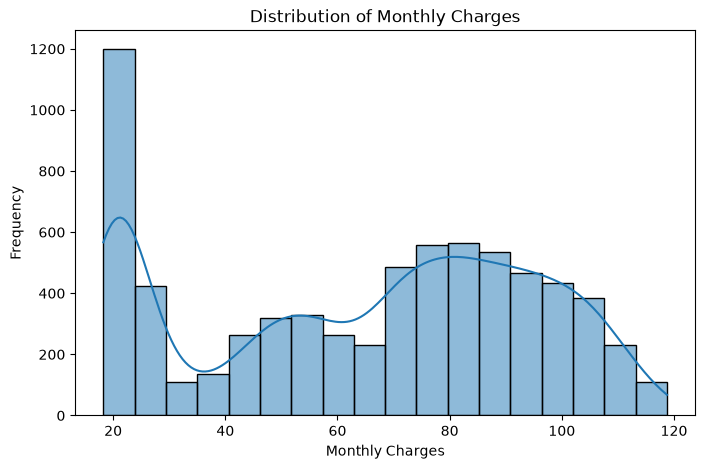

In [5]:
column = "MonthlyCharges"

print("Mean:", df[column].mean())
print("Median:", df[column].median())
print("Skewness:", df[column].skew())
print("Standard Deviation:", df[column].std())

plt.figure(figsize=(8, 5))
sns.histplot(df[column], kde=True)
plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")
plt.show()

### Question 11: 

### What is correlation?


Correlation measures the strength and direction of the relationship between two variables. It generally ranges from -1 to +1.

### Question 12: 

### Write Python code to create a correlation heatmap.

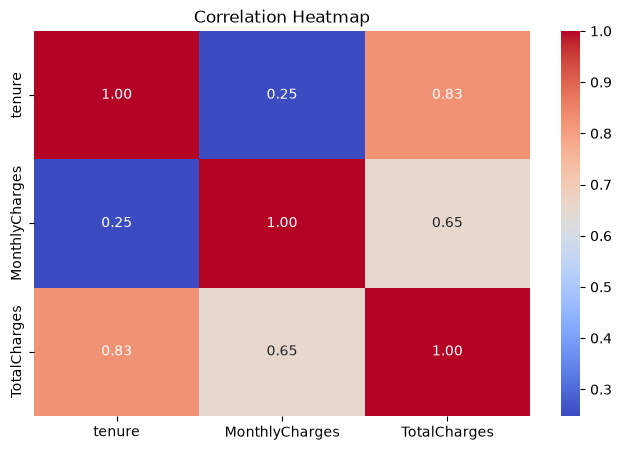

In [6]:
numeric_df = df[["tenure", "MonthlyCharges"]].copy()
numeric_df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

### Question 13: 

### What is the difference between correlation and causation?

Correlation means two variables are related. Causation means a change in one variable directly causes a change in another. Correlation alone does not prove causation.

### Question 14: 

### What is multicollinearity?


Multicollinearity occurs when two or more independent features are highly correlated with each other. It can make some Machine Learning model coefficients difficult to interpret.

### Question 15: 

### Write Python code to identify class imbalance in the target variable.

Class Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Class Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


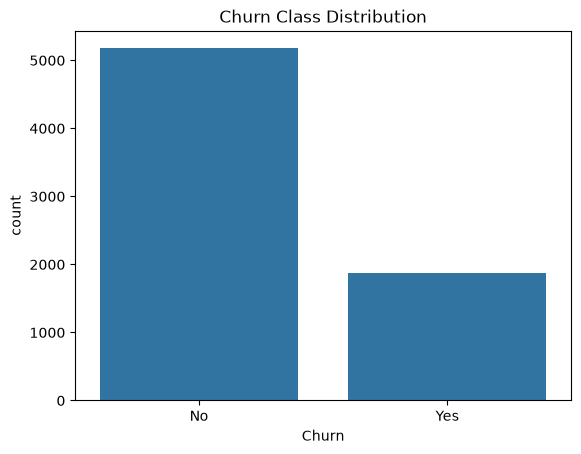

In [7]:
class_counts = df["Churn"].value_counts()
class_percentages = df["Churn"].value_counts(normalize=True) * 100

print("Class Counts:")
print(class_counts)

print("\nClass Percentages:")
print(class_percentages.round(2))

sns.countplot(data=df, x="Churn")
plt.title("Churn Class Distribution")
plt.show()

### Question 16: 

### Why should outliers not always be removed?


Outliers may represent genuine customer behavior or important business cases. Removing them without investigation can cause information loss and affect model performance.

### Question 17: 

### Write Python code to perform categorical analysis on the Contract feature.

Unique Categories:
['Month-to-month' 'One year' 'Two year']

Category Frequencies:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

Category Percentages:
Contract
Month-to-month    55.02
Two year          24.07
One year          20.91
Name: proportion, dtype: float64


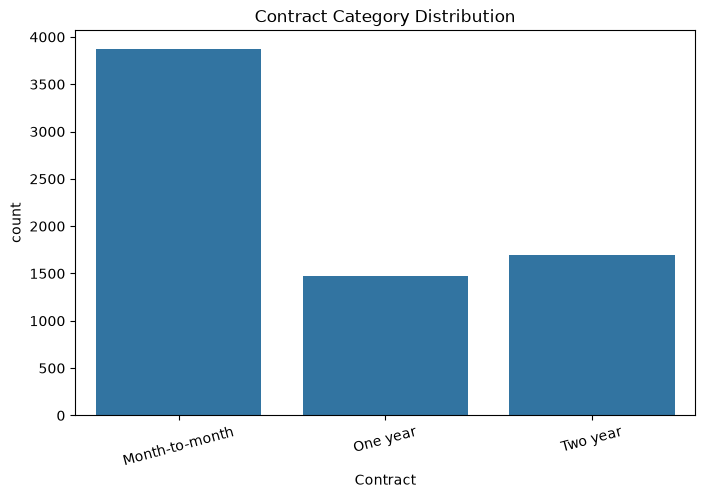

In [8]:
column = "Contract"

print("Unique Categories:")
print(df[column].unique())

print("\nCategory Frequencies:")
print(df[column].value_counts())

print("\nCategory Percentages:")
print((df[column].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=column)
plt.title("Contract Category Distribution")
plt.xticks(rotation=15)
plt.show()

### Question 18:

### Write Python code to generate a complete EDA summary.

In [9]:
print("===== DATASET OVERVIEW =====")
print("Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\n===== DATA TYPES =====")
print(df.dtypes)

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

print("\n===== DUPLICATE RECORDS =====")
print(df.duplicated().sum())

print("\n===== NUMERICAL SUMMARY =====")
print(df.describe())

print("\n===== CATEGORICAL SUMMARY =====")
print(df.describe(include="object"))

print("\n===== TARGET DISTRIBUTION =====")
print(df["Churn"].value_counts())
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

print("\n===== NUMERICAL CORRELATION =====")
summary_numeric = df[
    ["tenure", "MonthlyCharges"]
].copy()

summary_numeric["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print(summary_numeric.corr())

===== DATASET OVERVIEW =====
Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

===== DATA TYPES =====
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dt